# Lab 10A — Acoustic AI for Health: Respiratory Sound Classification (ICBHI)


**Authored by**: Seetha Parameswaran, BITS Pilani WILP

This is the first of three acoustic-AI labs, each a different *kind* of problem. Here the task is **supervised classification**: the ICBHI database gives us breath cycles labelled as normal, crackle, or wheeze, so we can train a classifier directly. (Contrast with 10B, where machine faults are unlabelled and force anomaly detection, and 10C, where 6000+ species force reliance on a pretrained model.)

We turn each annotated breath cycle into a **log-mel spectrogram** and train a small 2D CNN to distinguish the three classes. The medically interesting part is not the network — it is everything around it: respiratory datasets are **heavily imbalanced** (most cycles are normal), so accuracy is a misleading score, and the data must be **split by patient**, never by cycle, or the results are inflated.

## Learning Objectives

By the end of this lab you will be able to:

1. Convert clinically annotated breath cycles into **log-mel spectrogram** inputs
2. Train a small **CNN classifier** for normal / crackle / wheeze
3. Handle **class imbalance** with class weights (and know why accuracy fails here)
4. Perform a **patient-level split** and explain why cycle-level splitting inflates scores
5. Evaluate with **sensitivity, specificity, and the ICBHI score** rather than accuracy

## Dataset

**ICBHI 2017 Respiratory Sound Database** — 920 annotated recordings from 126 patients,
~6900 labelled breath cycles, collected with digital stethoscopes.

**Download (Kaggle mirror):**
```
pip install kaggle          # place kaggle.json in ~/.kaggle/
kaggle datasets download -d vbookshelf/respiratory-sound-database
unzip -q respiratory-sound-database.zip
```
Original source: ICBHI 2017 Challenge — https://bhichallenge.med.auth.gr/

**Folder layout** (set `ICBHI_ROOT` to the folder that actually holds the `.wav` files):
```
Respiratory_Sound_Database/
    audio_and_txt_files/          <-- ICBHI_ROOT points HERE
        101_1b1_Al_sc_Meditron.wav
        101_1b1_Al_sc_Meditron.txt    # cycle annotations: start end crackle wheeze
        ...
    patient_diagnosis.csv
```
Each `.txt` shares its stem with a `.wav` and has one row per breath cycle:
`start_sec  end_sec  crackle(0/1)  wheeze(0/1)`.


## 1. Setup

Expected dataset layout (ICBHI 2017 Respiratory Sound Database):
```
ICBHI_ROOT/
    101_1b1_Al_sc_Meditron.wav
    101_1b1_Al_sc_Meditron.txt      # cycle annotations: start end crackle wheeze
    ...
    filename_differences.txt
    ICBHI_challenge_diagnosis.txt
```
Each `.txt` (same stem as the `.wav`) has one row per breath cycle:
`start_sec  end_sec  crackle(0/1)  wheeze(0/1)`.

Set `ICBHI_ROOT` to your local path.

In [1]:
import os, glob, warnings
import numpy as np
import librosa
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(42)

ICBHI_ROOT = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/respiratory/respiratory_sound_database/Respiratory_Sound_Database/audio_and_txt_files"

SR          = 4000     # respiratory sounds live below 2 kHz -> 4 kHz is enough (Nyquist)
N_MELS      = 64
CYCLE_SEC   = 2.5      # pad/trim every breath cycle to a fixed length
N_FFT       = 256      # ~64 ms window at 4 kHz
HOP         = 64
CLASSES     = ["normal", "crackle", "wheeze"]  # (crackle+wheeze -> mapped to crackle for a clean 3-class demo)

print("librosa", librosa.__version__, "| numpy", np.__version__)
print("Fixed cycle length:", CYCLE_SEC, "s  |  sr:", SR)

librosa 0.10.1 | numpy 1.24.4
Fixed cycle length: 2.5 s  |  sr: 4000


In [2]:
print("wav:", len(glob.glob(os.path.join(ICBHI_ROOT, "*.wav"))))   # expect ~920
print("txt:", len(glob.glob(os.path.join(ICBHI_ROOT, "*.txt"))))   # expect ~920

wav: 920
txt: 920


## 2. Parse annotations → (wav, start, end, label, patient_id)

The **patient id** is the leading number in the filename (e.g. `101_...`).
We keep it so we can split by patient later — this is the single most important
step for an honest score. Same patient in train *and* test inflates everything.

In [3]:
def cycle_label(crackle, wheeze):
    # 3-class demo: any crackle -> 'crackle', wheeze-only -> 'wheeze', else 'normal'
    if crackle == 1:
        return "crackle"
    if wheeze == 1:
        return "wheeze"
    return "normal"

def parse_dataset(root):
    rows = []
    for txt in sorted(glob.glob(os.path.join(root, "*.txt"))):
        wav = txt[:-4] + ".wav"
        if not os.path.exists(wav):
            continue  # skip diagnosis/readme txt files with no matching wav
        stem = os.path.basename(wav)
        patient = stem.split("_")[0]
        with open(txt) as f:
            for line in f:
                p = line.split()
                if len(p) < 4:
                    continue
                start, end, cr, wh = float(p[0]), float(p[1]), int(p[2]), int(p[3])
                rows.append((wav, start, end, cycle_label(cr, wh), patient))
    return rows

rows = parse_dataset(ICBHI_ROOT)
print("Total breath cycles:", len(rows))
print("Unique patients    :", len({r[4] for r in rows}))

# class balance — expect a heavy 'normal' majority
from collections import Counter
print("Class balance      :", Counter(r[3] for r in rows))

Total breath cycles: 6898
Unique patients    : 126
Class balance      : Counter({'normal': 3642, 'crackle': 2370, 'wheeze': 886})


## 3. Cycle → log-mel spectrogram

Each annotated cycle is cut from its recording, resampled to 4 kHz,
padded/trimmed to a fixed 2.5 s, and turned into a 64-band log-mel image.

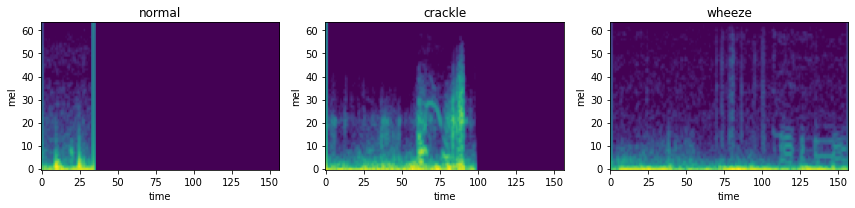

In [4]:
_target_len = int(CYCLE_SEC * SR)

def load_cycle(wav, start, end):
    y, _ = librosa.load(wav, sr=SR, offset=start, duration=max(end - start, 0.05))
    if len(y) < _target_len:
        y = np.pad(y, (0, _target_len - len(y)))
    else:
        y = y[:_target_len]
    return y

def to_logmel(y):
    m = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    return librosa.power_to_db(m, ref=np.max)

# quick visual sanity check: one example per class
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, cls in zip(ax, CLASSES):
    r = next(r for r in rows if r[3] == cls)
    a.imshow(to_logmel(load_cycle(r[0], r[1], r[2])), origin="lower", aspect="auto")
    a.set_title(cls); a.set_xlabel("time"); a.set_ylabel("mel")
plt.tight_layout(); plt.show()

## 4. Patient-level split

We assign whole **patients** to train or test — not individual cycles.
A model that hears patient 101 in training must not be tested on patient 101.

In [5]:
patients = sorted({r[4] for r in rows})
rng = np.random.default_rng(42)
rng.shuffle(patients)
n_test = max(1, int(0.25 * len(patients)))
test_patients  = set(patients[:n_test])
train_patients = set(patients[n_test:])

train_rows = [r for r in rows if r[4] in train_patients]
test_rows  = [r for r in rows if r[4] in test_patients]
print(f"Patients  train/test: {len(train_patients)} / {len(test_patients)}")
print(f"Cycles    train/test: {len(train_rows)} / {len(test_rows)}")

def build_xy(rset):
    X, y = [], []
    for wav, s, e, lab, _ in rset:
        X.append(to_logmel(load_cycle(wav, s, e)))
        y.append(CLASSES.index(lab))
    X = np.array(X)[..., np.newaxis].astype("float32")  # (N, mel, time, 1)
    return X, np.array(y)

X_train, y_train = build_xy(train_rows)
X_test,  y_test  = build_xy(test_rows)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Patients  train/test: 95 / 31
Cycles    train/test: 5434 / 1464
X_train: (5434, 64, 157, 1) | X_test: (1464, 64, 157, 1)


## 5. Small 2D CNN

A compact CNN — this trains on CPU in a few minutes on a subset.
Nothing fancy: the point is the *evaluation*, not the architecture.

In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_cnn(shape, n_classes):
    m = models.Sequential([
        layers.Input(shape=shape),
        layers.Conv2D(16, 3, activation="relu", padding="same"), layers.MaxPool2D(),
        layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPool2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"), layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"), layers.Dropout(0.3),
        layers.Dense(n_classes, activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

model = build_cnn(X_train.shape[1:], len(CLASSES))
model.summary()

2026-07-16 17:25:50.466892: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2026-07-16 17:25:50.466949: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2026-07-16 17:25:53.939685: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2026-07-16 17:25:53.939785: W tensorflow/stream_executor/cuda/cuda_driver.cc:269] failed call to cuInit: UNKNOWN ERROR (303)
2026-07-16 17:25:53.939903: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (seetha-HP-348-G4): /proc/driver/nvidia/version does not exist
2026-07-16 17:25:53.948313: I tensorflow/core/platform/cpu_f

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 157, 16)       160       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 78, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 78, 32)        4640      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 39, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 16, 39, 64)        18496     
                                                                 
 global_average_pooling2d (G  (None, 64)               0

## 6. Handling imbalance: class weights

`normal` dominates. Without weighting, the model learns to always say "normal"
and reports a high accuracy that means nothing. We up-weight the rare classes.

In [7]:
from sklearn.utils.class_weight import compute_class_weight

cw = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=15, batch_size=32,
    class_weight=class_weight,   # <-- the imbalance fix
    verbose=2,
)

Class weights: {'normal': 0.64, 'crackle': 0.9, 'wheeze': 3.01}


2026-07-16 17:26:03.707288: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 185606656 exceeds 10% of free system memory.


Epoch 1/15
145/145 - 21s - loss: 1.2426 - accuracy: 0.3090 - val_loss: 1.1997 - val_accuracy: 0.0564 - 21s/epoch - 148ms/step
Epoch 2/15
145/145 - 20s - loss: 1.1260 - accuracy: 0.1849 - val_loss: 1.1329 - val_accuracy: 0.0784 - 20s/epoch - 135ms/step
Epoch 3/15
145/145 - 18s - loss: 1.1222 - accuracy: 0.2354 - val_loss: 1.0798 - val_accuracy: 0.5319 - 18s/epoch - 124ms/step
Epoch 4/15
145/145 - 18s - loss: 1.1110 - accuracy: 0.3943 - val_loss: 1.1217 - val_accuracy: 0.4473 - 18s/epoch - 122ms/step
Epoch 5/15
145/145 - 22s - loss: 1.1060 - accuracy: 0.4164 - val_loss: 1.2246 - val_accuracy: 0.1581 - 22s/epoch - 152ms/step
Epoch 6/15
145/145 - 24s - loss: 1.0956 - accuracy: 0.4160 - val_loss: 1.1398 - val_accuracy: 0.1385 - 24s/epoch - 167ms/step
Epoch 7/15
145/145 - 24s - loss: 1.0917 - accuracy: 0.4348 - val_loss: 1.1148 - val_accuracy: 0.4571 - 24s/epoch - 167ms/step
Epoch 8/15
145/145 - 27s - loss: 1.0734 - accuracy: 0.4610 - val_loss: 1.1024 - val_accuracy: 0.4694 - 27s/epoch - 185

## 7. Evaluation — why accuracy is the wrong number

We report **per-class sensitivity and specificity** and the **ICBHI score**
= mean(sensitivity, specificity). This is the official challenge metric,
and it exists *because* accuracy rewards a lazy "always normal" model.

In [8]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
cm = confusion_matrix(y_test, y_pred, labels=range(len(CLASSES)))

print("Confusion matrix (rows = true, cols = pred):")
print("           " + "  ".join(f"{c:>8}" for c in CLASSES))
for i, c in enumerate(CLASSES):
    print(f"{c:>8}   " + "  ".join(f"{v:8d}" for v in cm[i]))

# ICBHI-style: sensitivity = correct abnormal / all abnormal ; specificity = correct normal / all normal
normal_idx = CLASSES.index("normal")
tn = cm[normal_idx, normal_idx]
n_normal = cm[normal_idx].sum()
specificity = tn / max(n_normal, 1)

abn = [i for i in range(len(CLASSES)) if i != normal_idx]
correct_abn = sum(cm[i, i] for i in abn)
n_abn = sum(cm[i].sum() for i in abn)
sensitivity = correct_abn / max(n_abn, 1)

icbhi = 0.5 * (sensitivity + specificity)
acc = np.trace(cm) / cm.sum()

print(f"\nAccuracy (misleading here): {acc:.3f}")
print(f"Sensitivity (abnormal)    : {sensitivity:.3f}")
print(f"Specificity (normal)      : {specificity:.3f}")
print(f"ICBHI score = mean(Se,Sp) : {icbhi:.3f}   <-- report THIS")

2026-07-16 17:32:04.650508: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 58841088 exceeds 10% of free system memory.


Confusion matrix (rows = true, cols = pred):
             normal   crackle    wheeze
  normal        146       520       158
 crackle         42       270        44
  wheeze         40       101       143

Accuracy (misleading here): 0.382
Sensitivity (abnormal)    : 0.645
Specificity (normal)      : 0.177
ICBHI score = mean(Se,Sp) : 0.411   <-- report THIS


## Takeaways

- **Task type:** supervised classification — every class is labelled, so no autoencoder is needed   (unlike 10B). The choice of model follows directly from the availability of labels. 
- **Front-end:** respiratory sound lives below ~2 kHz, so a 4 kHz sampling rate is sufficient;  a 64-band log-mel spectrogram captures crackles and wheezes well.
- **Imbalance:** roughly 85% of cycles are normal. Without class weights the model learns to always   predict "normal" and reports a high accuracy that has **zero clinical value** — which is exactly why   the field uses the **ICBHI score = ½(sensitivity + specificity)** instead of accuracy.
- **Splitting:** assigning whole **patients** to train or test is the single most important step.   A cycle-level split leaks the same patient into both sets and inflates every metric.
- **Metrics that matter clinically:** sensitivity (missing a disease is the costly error) and   specificity (false alarms burden the clinic), combined in the ICBHI score.

**Looking ahead (10A → 10B → 10C):** the feature pipeline barely changes across the three domains. 

What changes is the **problem definition** — labelled classes here (classify), unlabelled faults in industry (detect anomalies), and thousands of weakly-labelled classes in the environment (stand on a pretrained model). Recognising which of these you actually face is the real skill this module teaches.
